# 03 — Fine-tuning de NeurOST sur les paires nadir → KaRIn

**Le principe.** NeurOST a déjà appris, sur un million d'exemples à l'échelle du globe, à reconstruire la SSH à partir des traces d'altimètres. On part de ces poids (on ne recommence pas de zéro) et on continue l'apprentissage sur *nos* exemples : le réseau voit la trace nadir de SWOT, prédit une carte 128 × 128, on compare sa carte aux points KaRIn, et on corrige un peu les poids pour réduire l'écart. On répète ça sur tous les exemples, plusieurs fois.

**Le plan.**
1. Les données : Dataset et DataLoader
2. Le modèle et ses poids pré-entraînés
3. La loss : comment on compare une carte à des points
4. Une mesure lisible : la RMSE en cm
5. Les BatchNorm : pourquoi il faut les figer
6. L'optimiseur
7. La boucle d'entraînement
8. Lire les courbes
9. Regarder une prédiction
10. Le test, une seule fois

Les cases `___` sont à compléter (TODO 1 à 6).

In [1]:
import sys, copy
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

sys.path += ["/home/nora/projects/NeurOST", "/home/nora/projects/NeurOST/src",
             "/home/nora/projects/NeurOST/my_work/scripts"]
from dataset_swot import SwotNadirKarinDataset
from src.simvp_model import SimVP_Model_no_skip
from src.pytorch_losses import torch_tracked_mse_interp, interpolate_values

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)       # pour que deux exécutions donnent le même résultat
print(device)

/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda


/home/nora/miniconda3/envs/neurost_nora/lib/python3.12/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## 1. Les données : Dataset et DataLoader

- Le **Dataset** (`dataset_swot.py`) donne *un* exemple : `(entrée, cible)`.
- Le **DataLoader** les regroupe par **batch** de 4 : le réseau traite 4 exemples d'un coup, et on corrige les poids une fois par batch.
- `shuffle` : pour l'entraînement, on mélange l'ordre à chaque époque. Sinon le réseau voit toujours les mêmes exemples dans le même ordre (ici rangés par date), et chaque batch ressemble au précédent. Pour la validation, l'ordre ne change rien au résultat : on ne mélange pas.

In [2]:
dossier = "/home/nora/projects/NeurOST/my_work/notebooks"
kw = dict(npz_path=f"{dossier}/exemples_GS_feuille23.npz",
          csv_path=f"{dossier}/exemples_GS_feuille23.csv")

ds_train = SwotNadirKarinDataset(jeu="train", **kw)
ds_val = SwotNadirKarinDataset(jeu="val", **kw)
print(len(ds_train), "exemples train,", len(ds_val), "exemples val")

# TODO 1 : mélanger pour le train, pas pour la val (True / False)
dl_train = DataLoader(ds_train, batch_size=4, shuffle=True)
dl_val = DataLoader(ds_val, batch_size=4, shuffle=False)

x, y = next(iter(dl_train))
print("entrée :", tuple(x.shape))    # (batch, jours, canaux, 128, 128)
print("cible  :", tuple(y.shape))    # (batch, jours, points, [x_pix, y_pix, ssh])

250 exemples train, 52 exemples val
entrée : (4, 30, 1, 128, 128)
cible  : (4, 30, 2134, 3)


## 2. Le modèle et ses poids pré-entraînés

On construit d'abord l'architecture (avec des poids au hasard), puis on charge les poids appris par NeurOST, version **SSH seule** (notre entrée n'a pas de SST). Attention : un modèle qui vient d'être construit est en mode *entraînement*. On le passe tout de suite en mode évaluation (`model.eval()`), sinon le simple fait de l'appeler modifie déjà ses BatchNorm (voir partie 5).

Les réglages (`hid_S`, `hid_T`…) doivent être exactement ceux de l'entraînement d'origine, sinon les poids ne rentrent pas : on les reprend de `predict_ssh.py`.

**Le préfixe `module.`** : les poids ont été sauvegardés depuis un modèle entraîné sur plusieurs GPU (`DataParallel`), qui ajoute `module.` devant chaque nom de couche. Notre modèle n'a pas cette enveloppe, il faut donc retirer le préfixe pour que les noms correspondent.

In [3]:
model = SimVP_Model_no_skip(in_shape=(30, 1, 128, 128), model_type="gsta",
                            hid_S=8, hid_T=128, drop=0.2, drop_path=0.15).to(device)

chemin = "/home/nora/projects/NeurOST/input_data/model_weights/simvp_ssh_ns1000000_global_weights_epoch45"
sd = torch.load(chemin, map_location=device, weights_only=False)["model_state_dict"]
print("nom dans le fichier :", list(sd.keys())[0])

# TODO 2 : enlever "module." au début de chaque nom
# indice : k.removeprefix("module.")
sd = {k.removeprefix("module."): v for k, v in sd.items()}
model.load_state_dict(sd)
model.eval()      # un modèle neuf est en mode entraînement : sans ça, le moindre appel modifie les BatchNorm

poids_init = copy.deepcopy(sd)       # on garde les poids d'origine pour comparer à la fin
print(sum(p.numel() for p in model.parameters()) / 1e6, "millions de paramètres")

nom dans le fichier : module.enc.enc.0.conv.conv.weight
2.313857 millions de paramètres


## 3. La loss : comment on compare une carte à des points

Le réseau sort une **carte** par jour : `(batch, 30, 1, 128, 128)`. La cible, elle, est une liste de **points** KaRIn en coordonnées pixel.

`torch_tracked_mse_interp` (la loss de NeurOST) fait, pour chaque point KaRIn :
1. lit la valeur de la carte prédite à la position `(x_pix, y_pix)`, par interpolation bilinéaire entre les 4 pixels voisins ;
2. calcule l'écart au carré avec la SSH KaRIn ;
3. fait la moyenne sur les points réels (les zéros de remplissage sont ignorés).

**Pourquoi le jour 15 seulement ?** Nos cibles n'existent qu'au jour 15. La loss de NeurOST fait la moyenne sur les 30 jours : les 29 jours vides comptent pour 0, ce qui divise la loss par 30 sans rien apporter. On ne lui passe donc que le jour 15.

In [4]:
J = 15

def perte(pred, cible):
    # TODO 3 : ne garder que le jour J, en gardant l'axe du temps
    # indice : pred[:, J:J+1]  (pred[:, J] supprimerait l'axe, et la loss attend 5 dimensions)
    return torch_tracked_mse_interp(pred[:, J:J+1], cible[:, J:J+1])

with torch.no_grad():
    print("loss sur un batch :", perte(model(x.to(device)), y.to(device)).item())

loss sur un batch : 2.2813963890075684


## 4. Une mesure lisible : la RMSE en cm

La loss est en unités normalisées au carré : difficile à interpréter. On calcule aussi la **RMSE en cm** sur la validation, en repassant en mètres (× `std_ssh` = 0,0986 m).

- `model.eval()` : coupe le dropout, pour que la prédiction soit déterministe.
- `torch.no_grad()` : on ne calcule pas de gradients (on n'apprend pas ici), c'est plus rapide.

On la mesure **avant** tout entraînement : c'est le point de départ à battre. Pour se donner une échelle, prédire SSH = 0 partout donne environ 26 cm.

In [5]:
STD_SSH = 0.0986

def rmse_cm(model, dl):
    model.eval()
    somme, n = 0.0, 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            c = y[:, J]                                   # (batch, points, 3)
            reel = c[..., 2] != 0                         # vrais points (pas le remplissage)
            v = interpolate_values(pred[:, J], c[..., :2])
            somme += ((v - c[..., 2])[reel] ** 2).sum().item()
            n += reel.sum().item()
    return 100 * STD_SSH * (somme / n) ** 0.5

rmse_avant = rmse_cm(model, dl_val)
print(f"RMSE val avant fine-tuning : {rmse_avant:.2f} cm")

RMSE val avant fine-tuning : 13.24 cm


## 5. Les BatchNorm : pourquoi il faut les figer

Une couche **BatchNorm** recentre les valeurs qui la traversent avec une moyenne et un écart-type :
- en mode *évaluation*, elle utilise les statistiques apprises sur le million d'exemples d'origine ;
- en mode *entraînement*, elle utilise celles du batch courant, et met à jour les siennes.

Nos batchs font 4 exemples, avec 29 jours sur 30 vides : leurs statistiques n'ont rien à voir avec celles d'origine. Les laisser libres abîme le modèle. Testé ici : BatchNorm libres, la RMSE val passe de 13,2 à 15,9 cm après la première époque ; BatchNorm figées, elle descend à 12,0 cm.

On met donc le modèle en mode entraînement (ce qui active le **dropout**, utile contre le sur-apprentissage), puis on remet les BatchNorm en mode évaluation.

In [6]:
def mode_entrainement(model):
    model.train()                       # active dropout et drop_path
    for m in model.modules():           # parcourt toutes les couches
        # TODO 4 : si m est une BatchNorm2d, la remettre en mode évaluation
        # indices : isinstance(m, torch.nn.BatchNorm2d) ; m.eval()
        if isinstance(m, torch.nn.BatchNorm2d) : 
            m.eval()

## 6. L'optimiseur

L'optimiseur **Adam** décide de combien bouger chaque poids à partir des gradients. Le **learning rate** (`lr`) règle la taille des pas :
- trop grand : on détruit ce que NeurOST a appris ;
- trop petit : on n'avance pas.

Pour un fine-tuning, on prend petit. Testé : `1e-4` sur-apprend dès 3 ou 4 époques ; `3e-5` et `1e-5` arrivent au même plateau (~12,0 cm), `3e-5` plus vite.

In [7]:
opt = torch.optim.Adam(model.parameters(), lr=3e-5)
N_EPOQUES = 30

## 7. La boucle d'entraînement

Une **époque** = un passage sur tous les exemples d'entraînement, batch par batch. Pour chaque batch, quatre lignes :

1. `opt.zero_grad()` : remet les gradients à zéro (PyTorch les additionne d'un batch à l'autre sinon) ;
2. `loss = perte(model(x), y)` : le réseau prédit, on mesure l'erreur ;
3. `loss.backward()` : calcule, pour chaque poids, dans quel sens le bouger pour réduire l'erreur (le gradient) ;
4. `opt.step()` : bouge les poids d'un petit pas dans ce sens.

À la fin de chaque époque, on mesure la RMSE sur la validation, des exemples que le réseau ne voit jamais pendant l'apprentissage. On **garde les poids de la meilleure époque** : la dernière n'est pas forcément la meilleure (voir partie 8).

In [8]:
historique = {"loss_train": [], "rmse_val": []}
meilleure_rmse = rmse_avant
meilleurs_poids = copy.deepcopy(model.state_dict())
meilleure_epoque = 0

for epoque in range(1, N_EPOQUES + 1):
    mode_entrainement(model)
    total = 0.0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        # TODO 5 : les quatre lignes de l'apprentissage
        opt.zero_grad()                       # 1. remettre les gradients à zéro
        loss = perte(model(x), y)                # 2. prédire et mesurer l'erreur
        loss.backward()                       # 3. calculer les gradients
        opt.step()                       # 4. bouger les poids
        total += loss.item()

    rmse_val = rmse_cm(model, dl_val)
    historique["loss_train"].append(total / len(dl_train))
    historique["rmse_val"].append(rmse_val)

    # TODO 6 : si c'est la meilleure RMSE val jusqu'ici, la retenir et copier les poids
    if rmse_val < meilleure_rmse:
        meilleure_rmse = rmse_val
        meilleurs_poids = copy.deepcopy(model.state_dict())
        meilleure_epoque = epoque

    print(f"époque {epoque:2d}  loss train {historique['loss_train'][-1]:.3f}  RMSE val {rmse_val:.2f} cm")

model.load_state_dict(meilleurs_poids)
torch.save(meilleurs_poids, f"{dossier}/poids_finetune_feuille23.pt")
print(f"meilleure époque : {meilleure_epoque}, RMSE val {meilleure_rmse:.2f} cm (avant : {rmse_avant:.2f} cm)")

époque  1  loss train 1.701  RMSE val 12.25 cm
époque  2  loss train 1.603  RMSE val 12.10 cm
époque  3  loss train 1.577  RMSE val 12.07 cm
époque  4  loss train 1.543  RMSE val 12.07 cm
époque  5  loss train 1.542  RMSE val 12.04 cm
époque  6  loss train 1.514  RMSE val 12.08 cm
époque  7  loss train 1.500  RMSE val 12.03 cm
époque  8  loss train 1.486  RMSE val 12.03 cm
époque  9  loss train 1.474  RMSE val 12.07 cm
époque 10  loss train 1.459  RMSE val 12.16 cm
époque 11  loss train 1.438  RMSE val 12.15 cm
époque 12  loss train 1.437  RMSE val 12.12 cm
époque 13  loss train 1.428  RMSE val 12.12 cm
époque 14  loss train 1.396  RMSE val 12.16 cm
époque 15  loss train 1.379  RMSE val 12.21 cm
époque 16  loss train 1.364  RMSE val 12.19 cm
époque 17  loss train 1.340  RMSE val 12.40 cm
époque 18  loss train 1.350  RMSE val 12.21 cm
époque 19  loss train 1.354  RMSE val 12.24 cm
époque 20  loss train 1.306  RMSE val 12.24 cm
époque 21  loss train 1.286  RMSE val 12.47 cm
époque 22  lo

## 8. Lire les courbes

- **loss train** (à gauche) : l'erreur sur les exemples que le réseau voit. Elle baisse presque toujours : à force, il finit par les apprendre par cœur.
- **RMSE val** (à droite) : l'erreur sur des exemples jamais vus. C'est elle qui compte.

Si la loss train continue de baisser pendant que la RMSE val remonte, c'est du **sur-apprentissage** : le réseau mémorise nos 250 exemples au lieu d'apprendre quelque chose de général. C'est pour ça qu'on garde la meilleure époque plutôt que la dernière.

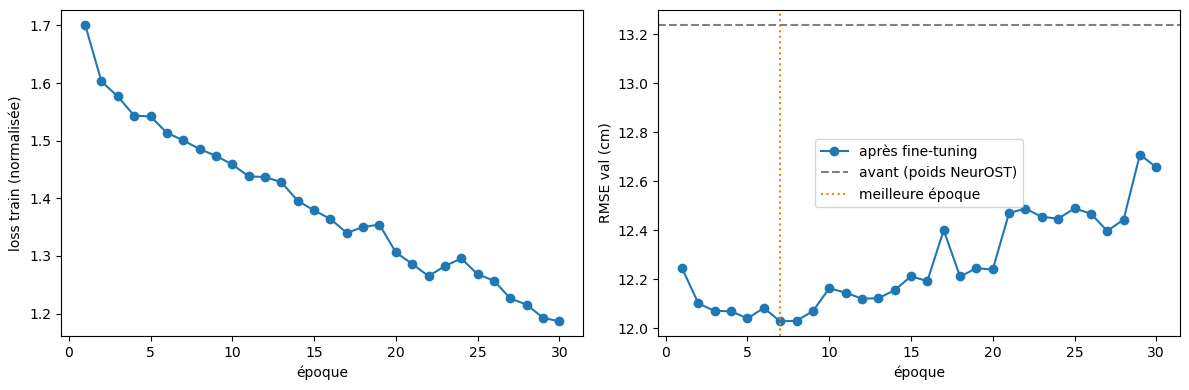

In [9]:
ep = np.arange(1, len(historique["rmse_val"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, historique["loss_train"], "o-")
axes[0].set_xlabel("époque"); axes[0].set_ylabel("loss train (normalisée)")
axes[1].plot(ep, historique["rmse_val"], "o-", label="après fine-tuning")
axes[1].axhline(rmse_avant, color="gray", ls="--", label="avant (poids NeurOST)")
axes[1].axvline(meilleure_epoque, color="C1", ls=":", label="meilleure époque")
axes[1].set_xlabel("époque"); axes[1].set_ylabel("RMSE val (cm)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Regarder une prédiction

Un chiffre ne suffit pas : on regarde une carte. Pour un exemple de validation : l'entrée (la trace nadir), la prédiction avant et après fine-tuning, et la vérité KaRIn. Tout est en coordonnées pixel, et repassé en mètres (`ssh × std + mean`).

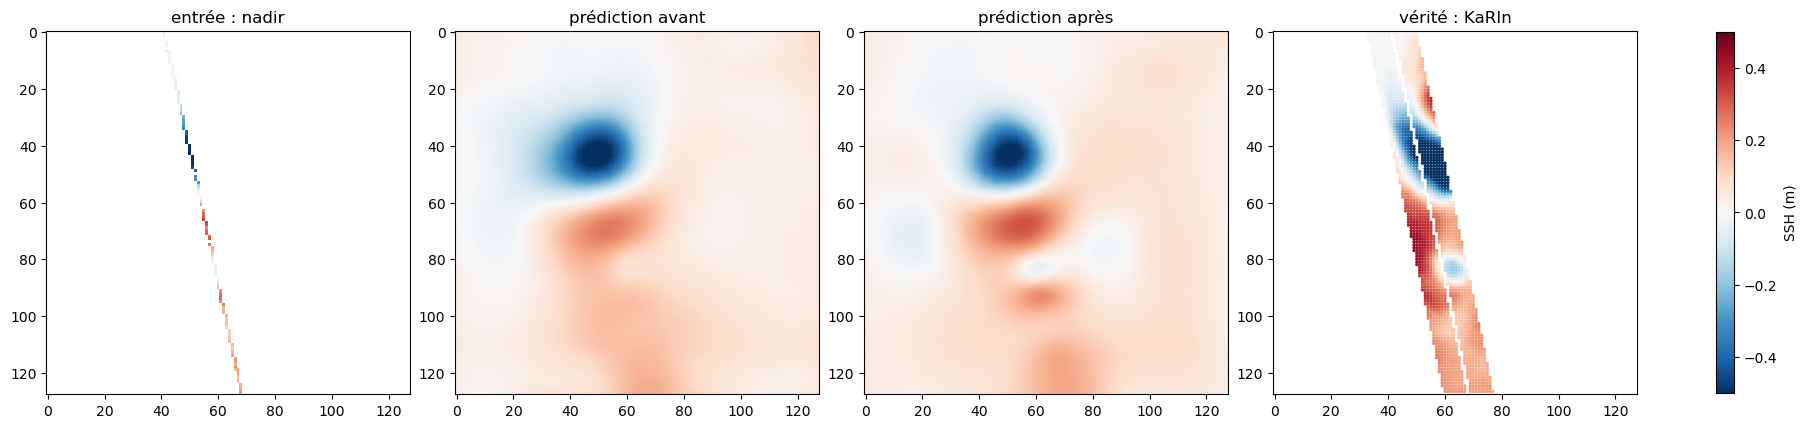

<All keys matched successfully>

In [10]:
MEAN_SSH = 0.074
i = 10                                             # un exemple de validation
x1, y1 = ds_val[i]
x1 = x1[None].to(device)                           # ajoute l'axe batch : (1, 30, 1, 128, 128)

def carte(poids):
    model.load_state_dict(poids)
    model.eval()
    with torch.no_grad():
        return model(x1)[0, J, 0].cpu().numpy() * STD_SSH + MEAN_SSH

avant, apres = carte(poids_init), carte(meilleurs_poids)

entree = x1[0, J, 0].cpu().numpy()
entree = np.where(entree != 0, entree * STD_SSH + MEAN_SSH, np.nan)
c = y1[J][(y1[J] != 0).any(-1)].numpy()

kw_c = dict(cmap="RdBu_r", vmin=-0.5, vmax=0.5)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), constrained_layout=True)
axes[0].imshow(entree, **kw_c, interpolation="nearest"); axes[0].set_title("entrée : nadir")
axes[1].imshow(avant, **kw_c); axes[1].set_title("prédiction avant")
axes[2].imshow(apres, **kw_c); axes[2].set_title("prédiction après")
im = axes[3].scatter(c[:, 0], c[:, 1], c=c[:, 2] * STD_SSH + MEAN_SSH, s=2, **kw_c)
axes[3].set_xlim(-0.5, 127.5); axes[3].set_ylim(127.5, -0.5); axes[3].set_aspect("equal")
axes[3].set_title("vérité : KaRIn")
fig.colorbar(im, ax=axes, label="SSH (m)", shrink=0.8)
plt.show()

model.load_state_dict(meilleurs_poids)            # on remet les meilleurs poids

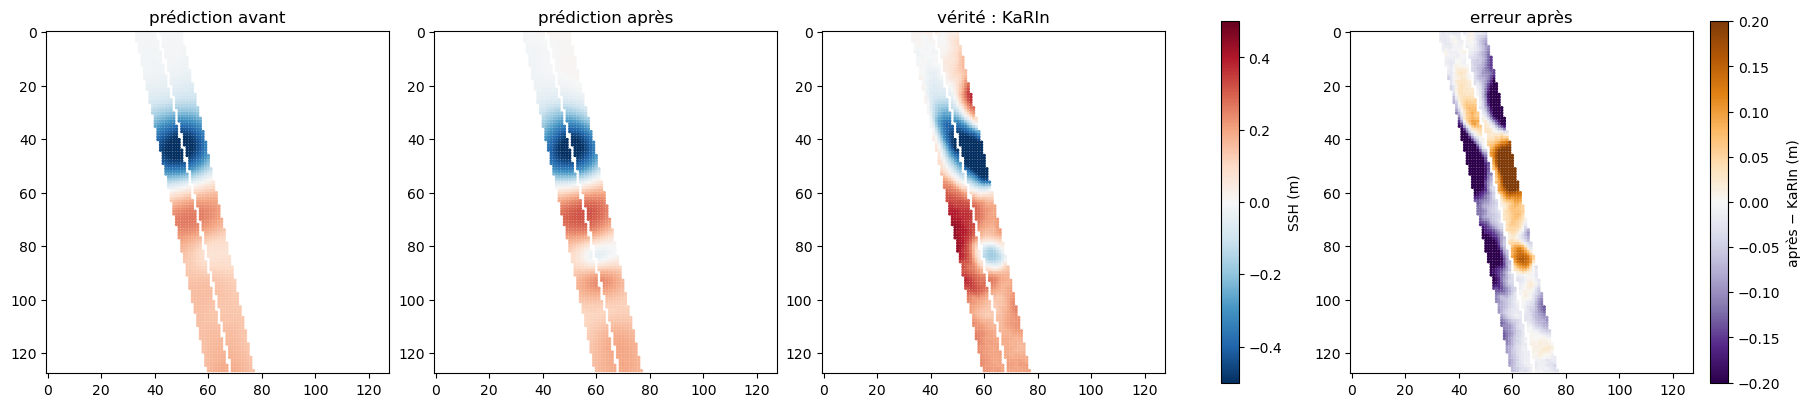

RMSE sous la fauchée, cet exemple : avant 15.2 cm, après 13.7 cm


In [11]:
from scipy.ndimage import map_coordinates

verite = c[:, 2] * STD_SSH + MEAN_SSH
# valeur de chaque carte sous chaque point KaRIn (interpolation bilinéaire, comme la loss)
sous_avant = map_coordinates(avant, [c[:, 1], c[:, 0]], order=1)
sous_apres = map_coordinates(apres, [c[:, 1], c[:, 0]], order=1)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), constrained_layout=True)
for ax, v, titre in zip(axes[:3], [sous_avant, sous_apres, verite],
                        ["prédiction avant", "prédiction après", "vérité : KaRIn"]):
    im = ax.scatter(c[:, 0], c[:, 1], c=v, s=2, **kw_c)
    ax.set_title(titre)
err = axes[3].scatter(c[:, 0], c[:, 1], c=sous_apres - verite, s=2, cmap="PuOr_r", vmin=-0.2, vmax=0.2)
axes[3].set_title("erreur après")
for ax in axes:
    ax.set_xlim(-0.5, 127.5); ax.set_ylim(127.5, -0.5); ax.set_aspect("equal")
fig.colorbar(im, ax=axes[:3], label="SSH (m)", shrink=0.8)
fig.colorbar(err, ax=axes[3], label="après − KaRIn (m)", shrink=0.8)
plt.show()

rmse = lambda v: 100 * np.sqrt(np.mean((v - verite) ** 2))
print(f"RMSE sous la fauchée, cet exemple : avant {rmse(sous_avant):.1f} cm, après {rmse(sous_apres):.1f} cm")

## 10. Le test, une seule fois

On a utilisé la validation pour choisir le learning rate, le nombre d'époques et la meilleure époque : son score est donc un peu flatteur. Le **test** n'a servi à aucun choix, c'est la mesure honnête. On ne le regarde qu'à la fin, et on ne revient pas changer des réglages après l'avoir vu.

In [12]:
dl_test = DataLoader(SwotNadirKarinDataset(jeu="test", **kw), batch_size=4)

model.load_state_dict(poids_init)
rmse_test_avant = rmse_cm(model, dl_test)
model.load_state_dict(meilleurs_poids)
rmse_test_apres = rmse_cm(model, dl_test)
print(f"RMSE test : {rmse_test_avant:.2f} cm avant  ->  {rmse_test_apres:.2f} cm après fine-tuning")

RMSE test : 12.52 cm avant  ->  11.79 cm après fine-tuning


## Ce qu'il faut retenir

- On ne réapprend pas NeurOST : on **ajuste** ses poids avec un petit learning rate, en partant de ce qu'il sait déjà.
- La loss compare la carte prédite aux points KaRIn par **interpolation**, au jour 15 seulement.
- Les **BatchNorm** restent figées : nos petits batchs ne ressemblent pas aux données d'origine.
- On choisit avec la **validation**, on conclut avec le **test**.
- Avec 250 exemples, le **sur-apprentissage** arrive vite : on garde la meilleure époque.

**Question ouverte :** le gain plafonne vers 12 cm. Avec une seule trace nadir, le réseau n'a pas d'information sur ce qui se passe à 60 km de part et d'autre. Ajouter les autres altimètres sur les 30 jours (comme NeurOST d'origine) devrait aider davantage que plus d'époques.